# The redesign's north star, guardrails, leading inputs, resistant lines and seven-line page: what should the scheme pay for, and what did paying for hours cost?

**Week 4, Monday, chapter 9 of 11, the third case chapter.** It applies four of the morning's
topics: *North-star and guardrail metrics*, taught in `C2_W04_D01_02_north_star_guardrails_STUDENT.ipynb`;
*Leading against lagging indicators*, taught in `C2_W04_D01_03_leading_lagging_STUDENT.ipynb`;
*Gaming, and definitions that resist it*, taught in
`C2_W04_D01_05_gaming_resistant_definitions_STUDENT.ipynb`; and *The metric definition
artifact*, taught in `C2_W04_D01_06_metric_definition_artifact_STUDENT.ipynb`. Levels 3 to 5 of
the case's six: the trap priced in rupees, the definition that resists it, the caveats an
engineer names aloud, and a second route in SQL.

**The case.** Uber's Hyderabad city team launched a peak-hour earnings guarantee on Monday
31 August 2026: a floor of Rs 300 per peak online hour, with Uber paying the gap between a
driver's trip earnings and the floor as a top-up. Six weeks on, peak online hours are up 24
percent, completed peak trips up 3 percent, and the top-up has cost Rs 1.9 crore.

> *Illustrative case: the company is real, the situation and the data are synthetic, built for this class.*

Notebook 08 found the fall in the full data: trips per peak online hour fell from 1.90 to 1.58
while rider requests rose, and 180 drivers (15 percent) logged 2.1 times their hours with 12
percent fewer trips, 72 percent of their new hours in the three thin outer zones.

**Who needs the answer.** The city head, who must say by Friday what the scheme pays for, and
the finance partner, who holds the top-up budget. A scheme that keeps paying for hours keeps
paying drivers to sit online in zones with no riders.

**The questions on the way.**

1. How much of the Rs 1.9 crore went to driver-weeks that accepted fewer than half their offers?
2. What do the north star and its three guardrails read, before and after?
3. Which number settled first?
4. Which doubts does the fall survive, and which stay open?
5. Does SQL reach the same totals as pandas?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

def check(name, ok):
    print("PASS" if ok else "FAIL", name)

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
INK, VIOLET, ROSE, LAV, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#D9A7FF", "#6B6690"

dw = pd.read_csv("../data/C2_W04_D01_driver_weeks_STUDENT.csv")
zw = pd.read_csv("../data/C2_W04_D01_zone_weeks_STUDENT.csv")
dw["window"] = dw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
zw["window"] = zw["week_start"].lt("2026-08-31").map({True: "before", False: "after"})
after = dw[dw["window"] == "after"].copy()
after["acceptance"] = after["peak_accepted"] / after["peak_offers"]
print(f"{len(after):,} driver-weeks after the launch; top-up paid Rs {after['topup_rs'].sum() / 1e7:.2f} crore")

6,500 driver-weeks after the launch; top-up paid Rs 1.90 crore


## How much of the Rs 1.9 crore went to driver-weeks that accepted fewer than half their offers?

**Predict before you run.** What share of the top-up went to driver-weeks whose accepted share
was under 0.5? a) 15 percent; b) 39 percent; c) 61 percent; d) 88 percent.

This cell splits the top-up at an accepted share of 0.5 and draws the two parts.

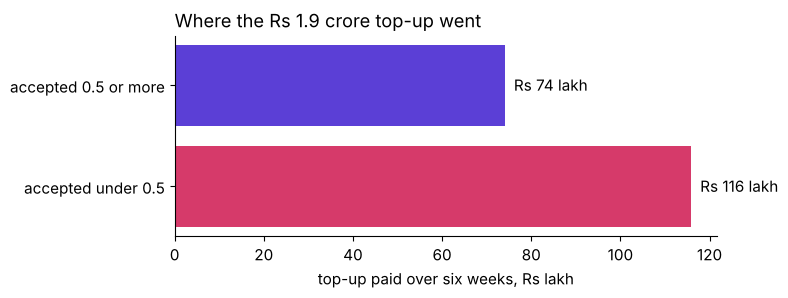

share to driver-weeks under 0.5: 0.61


In [2]:
low = after.loc[after["acceptance"] < 0.5, "topup_rs"].sum()
high = after.loc[after["acceptance"] >= 0.5, "topup_rs"].sum()
fig, ax = plt.subplots(figsize=(7.0, 2.6))
ax.barh(["accepted under 0.5", "accepted 0.5 or more"], [low / 1e5, high / 1e5], color=[ROSE, VIOLET])
for y, v in enumerate([low, high]):
    ax.text(v / 1e5 + 2, y, f"Rs {v / 1e5:.0f} lakh", va="center")
ax.set_xlabel("top-up paid over six weeks, Rs lakh")
ax.set_title("Where the Rs 1.9 crore top-up went", loc="left")
plt.show()
print(f"share to driver-weeks under 0.5: {low / (low + high):.2f}")

**What happened.** The answer is c: Rs 1.159 crore, 61 percent of the Rs 1.9 crore, went to
driver-weeks that accepted fewer than half the offers they were shown, and Rs 74 lakh went to
the rest. Had only the driver-weeks at or above 0.5 been paid, and had every driver behaved the
same, the six weeks would have cost Rs 74 lakh. A new rule changes behaviour, so Rs 74 lakh is
the least the six weeks would have cost under it. What the redesign would save, under a stated
assumption about how drivers respond, is round 3's question after lunch, priced in notebook 10.

## What do the north star and its three guardrails read, before and after?

The redesign's page, the seven lines of chapter 6, line by line:

| Line | What it says |
|---|---|
| Numerator | Trips completed inside the peak windows, one per paying rider: Uber's annual report counts an UberX Share ride with three paying riders as three trips |
| Denominator | Enrolled drivers online at least one peak hour that week, with the count printed beside the rate |
| Window | The calendar week |
| Exclusions | Trips cancelled by either side, test accounts, trips outside the windows |
| What it does not reward | Hours online; offers declined; a shrinking enrolled base, since fewer drivers in the count would raise the rate with no extra trip |
| Guardrails | For riders: offers accepted over offers shown, at or above an acceptance floor the city sets, and the median rider wait at peak. For the budget: top-up per completed trip |
| Gaming note | Guardrail 1 catches declining and cherry-picking; guardrail 2, supply that stops serving riders; guardrail 3, a top-up that runs away from the trips it pays for |

This cell computes the north star and the three guardrails for each window.

In [3]:
online = dw[dw["peak_online_hours"] > 0]
board = pd.DataFrame({
    "north_star_trips_per_online_driver_week": (online.groupby("window")["peak_trips"].sum()
                                                / online.groupby("window").size()).round(2),
    "online_driver_weeks": online.groupby("window").size(),
    "acceptance": (dw.groupby("window")["peak_accepted"].sum() / dw.groupby("window")["peak_offers"].sum()).round(3),
    "median_wait": zw.groupby("window")["median_wait_min"].median(),
    "topup_per_trip_rs": (dw.groupby("window")["topup_rs"].sum() / dw.groupby("window")["peak_trips"].sum()).round(1),
}).loc[["before", "after"]]
board.T

window,before,after
north_star_trips_per_online_driver_week,35.760,35.89
online_driver_weeks,6270.000,6434.00
acceptance,0.863,0.73
median_wait,4.800,4.60
topup_per_trip_rs,0.000,82.30


**What happened.** The north star read 35.76 trips per online driver-week before and 35.89
after: hours rose 24 percent and the number the scheme exists for barely moved. Acceptance
fell from 0.863 to 0.730, the median wait went from 4.8 to 4.6 minutes, and the top-up cost
Rs 82.3 per completed trip after the launch, against nothing before.

## Which number settled first?

Chapter 3's chase named the two kinds: a **leading** input moves before the number the plan is
judged on, while the team can still act; a **lagging** one confirms it later. This cell draws
the weekly share of offers accepted beside bookings per online hour.

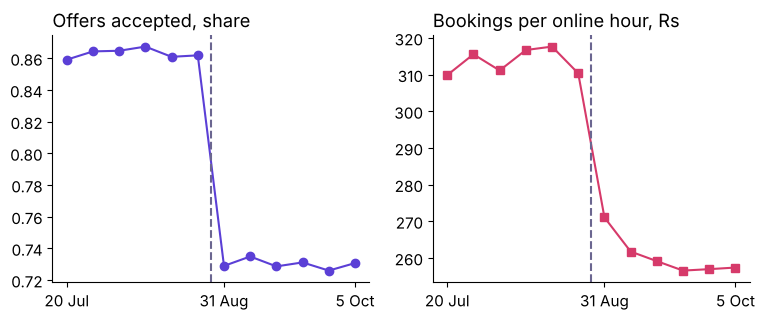

,acceptance,rs_per_hour
week_start,,
2026-08-31,0.729,271.035
2026-09-07,0.735,261.722
2026-09-14,0.729,259.107


In [4]:
wk = dw.groupby("week_start")[["peak_accepted", "peak_offers", "peak_bookings_rs", "peak_online_hours"]].sum()
wk["acceptance"] = wk["peak_accepted"] / wk["peak_offers"]
wk["rs_per_hour"] = wk["peak_bookings_rs"] / wk["peak_online_hours"]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(9.0, 3.2))
a1.plot(range(12), wk["acceptance"], marker="o", color=VIOLET)
a1.set_title("Offers accepted, share", loc="left")
a2.plot(range(12), wk["rs_per_hour"], marker="s", color=ROSE)
a2.set_title("Bookings per online hour, Rs", loc="left")
for a in (a1, a2):
    a.axvline(5.5, color=MUTED, linestyle="--")
    a.set_xticks([0, 6, 11], ["20 Jul", "31 Aug", "5 Oct"])
plt.show()
wk.loc[["2026-08-31", "2026-09-07", "2026-09-14"], ["acceptance", "rs_per_hour"]].round(3)

**What happened.** Acceptance dropped to its new level in the launch week (0.729) and stayed
there; bookings per online hour fell to Rs 271 in the launch week and kept falling to Rs 262
and Rs 259 over the next two. Acceptance settled two weeks before bookings per hour did, which
is what a leading input is for: a city team watching it would have seen the gaming in week one.

## Which doubts does the fall survive, and which stay open?

**Predict before you run.** Take out the 140 drivers who joined after the launch. What does
trips per peak online hour read for the six weeks after? a) 1.90; b) 1.79; c) 1.58; d) 1.19.

This cell restates the after-window rate under each cut the data can make. New in it: a
dictionary holds each slice of the table under its name, and
`{name: ... for name, d in slices.items()}` runs the same division, trips over hours, on every
slice; `.nlargest(3)` picks the three weeks with the most requests, and the drivers who joined
before the launch are the ids up to `d_1060`.

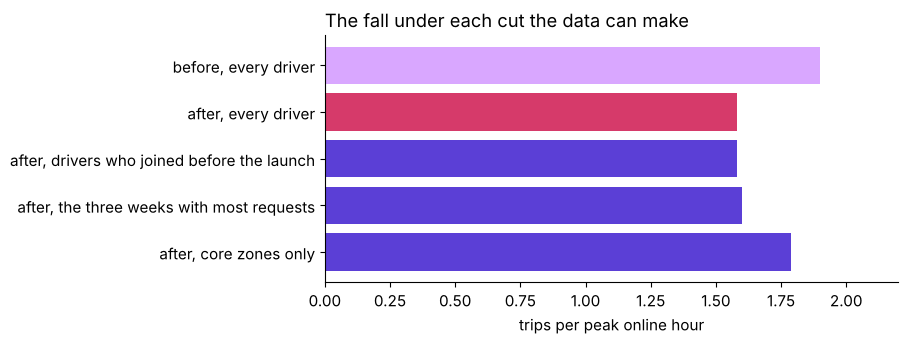

before, every driver                           1.90
after, every driver                            1.58
after, drivers who joined before the launch    1.58
after, the three weeks with most requests      1.60
after, core zones only                         1.79
dtype: float64

In [5]:
OUTER = ["Shamshabad", "Rajendranagar", "Patancheru"]
busiest = zw.groupby("week_start")["peak_requests"].sum().nlargest(3).index
slices = {
    "before, every driver": dw[dw["window"] == "before"],
    "after, every driver": after,
    "after, drivers who joined before the launch": after[after["driver_id"] <= "d_1060"],
    "after, the three weeks with most requests": dw[dw["week_start"].isin(busiest)],
    "after, core zones only": after[~after["zone_mode"].isin(OUTER)],
}
cuts = pd.Series({name: round(d["peak_trips"].sum() / d["peak_online_hours"].sum(), 2)
                  for name, d in slices.items()})
fig, ax = plt.subplots(figsize=(7.4, 3.2))
ax.barh(cuts.index[::-1], cuts.values[::-1], color=[VIOLET, VIOLET, VIOLET, ROSE, LAV])
ax.set_xlim(0, 2.2)
ax.set_xlabel("trips per peak online hour")
ax.set_title("The fall under each cut the data can make", loc="left")
plt.show()
cuts

**What happened.** The answer is c: without the 140 new drivers the rate after the launch is
still 1.58, so the new drivers do not explain the fall. In the three weeks with the most rider
requests of all twelve (the first three after the launch, still in the rains) the rate was
already 1.60, so the monsoon's end cannot explain the fall: demand was at its highest and the
fall was there. In the nine core zones the rate fell from 1.90 to 1.79, so most of the fall
sits in the three outer zones. Three doubts stay open: drivers on two apps (the data holds
weekly totals, so it cannot show a decline made because another app's trip was under way),
who chose to enrol (every driver here enrolled, so no group stayed out to compare with), and
cause (only a test of the redesign settles whether the scheme or the season moved the
number).

## Does SQL reach the same totals as pandas?

This cell loads `driver_weeks` into an in-memory SQLite database (a small database that lives
inside Python) and sums the same columns with one `GROUP BY`, then compares the two routes;
`1.0 *` makes SQL divide with decimals.

In [6]:
import sqlite3
con = sqlite3.connect(":memory:")
dw.to_sql("driver_weeks", con, index=False)
sql = pd.read_sql("""
    SELECT window, SUM(peak_online_hours) AS hours, SUM(peak_trips) AS trips,
           ROUND(1.0 * SUM(peak_trips) / SUM(peak_online_hours), 2) AS trips_per_hour
    FROM driver_weeks GROUP BY window ORDER BY window DESC""", con).set_index("window")
sql

,hours,trips,trips_per_hour
window,,,
before,118000,224200,1.90
after,146300,230900,1.58


In [7]:
check("61 percent of the top-up went to driver-weeks under 0.5", round(low / (low + high), 2) == 0.61)
check("Rs 1.159 crore and Rs 74 lakh", (low, high) == (11590000, 7410000))
check("the north star reads 35.76 before and 35.89 after", list(board.iloc[:, 0]) == [35.76, 35.89])
check("acceptance settled in the launch week at 0.729", round(wk.loc["2026-08-31", "acceptance"], 3) == 0.729)
check("the fall survives without the 140 new drivers", cuts["after, drivers who joined before the launch"] == 1.58)
check("the three weeks with most requests already read 1.60", cuts["after, the three weeks with most requests"] == 1.60)
check("SQL and pandas agree on hours and trips", list(sql["hours"]) == [118000, 146300] and list(sql["trips"]) == [224200, 230900])

PASS 61 percent of the top-up went to driver-weeks under 0.5
PASS Rs 1.159 crore and Rs 74 lakh
PASS the north star reads 35.76 before and 35.89 after
PASS acceptance settled in the launch week at 0.729
PASS the fall survives without the 140 new drivers
PASS the three weeks with most requests already read 1.60
PASS SQL and pandas agree on hours and trips


## What does chapter 9 answer?

1. Rs 1.159 crore, 61 percent of the top-up, went to driver-weeks that accepted fewer than
   half their offers; Rs 74 lakh went to the rest. Notebook 10 prices what the redesign would
   save.
2. The north star barely moved (35.76 to 35.89 trips per online driver-week); acceptance fell
   from 0.863 to 0.730, waits went from 4.8 to 4.6 minutes, and the top-up cost Rs 82.3 a trip.
3. Acceptance settled in the launch week, two weeks before bookings per hour did.
4. The fall survives the new drivers (1.58) and the three weeks with most requests (1.60);
   drivers on two apps, who chose to enrol and cause stay open.
5. SQL's `GROUP BY` returns the same hours and trips as pandas.

**The check a senior analyst runs.** Price the trap in rupees, write every line of the
definition, name what the data cannot show and the fact that would settle it, and reach the
totals a second way before anything leaves the team. Notebook 10 then puts the page under attack
and prices the redesign's saving.

**In the interview.** [F] North star against guardrail, with one example pair: completed
peak trips per enrolled driver per week, guarded by the share of offers accepted, which
catches a driver who stays online and declines. The tentative faculty block this afternoon
designs the test that would settle cause.